# Single window analysis

Change the settings and **Run All**. Code lives next to this notebook:

| file | what |
|---|---|
| `window.py` | load data, rule check per candle, trades in the window |
| `chart.py` | the plotly figure |
| `tables.py` | styled tables |
| `theme.py` | design: colors, EMA list, zone colors, layout |

**EMA test (`EMA_SET`):** `'9_21_200'` uses EMA 9/21/200, `'13_48_200'` uses EMA 13/48/200 - never both at the same time.

**Momentum (docs/ema.md, 15m):** fast > middle > 200 = BULL · 200 > middle > fast = BEAR · middle EMA (21 or 48) flat (moved < 0.25 ATR in 2h) or not in the middle = NONE · fast EMA (9 or 13) slope < `SLOPE_MIN` ATR per 15m candle in the trend direction = NONE

**Entry (docs/entry.md) = momentum only:** on each completed 5m candle → **BULL = LONG**, **BEAR = SHORT**, **NONE = no entry**. Enter at the next candle's open. Slopes, distances, touches and zones are ML features only.

**Stop loss (docs/stop_loss.md):** `STOP_LOSS` initial stop · once the trade reaches +`TRAIL_STEP` the stop follows the best price `TRAIL_GAP` behind (never moves back) · `TAKE_PROFIT` exit. All in ATR multiples (atr_5m at the signal candle); `LEVERAGE` only scales ROE.

`OVERLAP = True`: every momentum candle opens its own trade (many trades per window).
`OVERLAP = False`: one trade at a time, signals while in a trade are skipped.

Zones are drawn on the chart as information only - they do not filter the entry.

**Momentum move (section 4):** no stop / TP - hold while the momentum lasts, exit at the open of the first candle without it. Best move in favour (MFE), worst move against (MAE) and exit move, all in ATR (atr_5m of the signal candle).

In [28]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, '..')              # project root: stop_loss.py, zone_create.py, data/

from analysis.window import build_window
from analysis import tables, chart
from analysis.momentum_move import window_moves, momentum_moves, summary

# ---------------- settings ----------------
SYMBOL      = 'BTCUSDT'
START       = '2024-12-05 00:55'      # first candle (UTC)
CANDLES     = (30, 60)                # candle range from START: (30, 60) = candle 30 to 59 | or a number, e.g. 30
LEVERAGE    = 5                      # only scales ROE (price move x LEVERAGE); stop / trail / TP are in ATR
STOP_LOSS   = 5                       # initial stop, x ATR(5m) at the signal candle (5 ATR ~ 1% price on the median coin)
TRAIL_STEP  = 5                       # trail starts once the trade is +TRAIL_STEP x ATR in profit
TRAIL_GAP   = None                    # stop follows the best price this many ATR behind (None = TRAIL_STEP); 2.5 locks more profit
TAKE_PROFIT = 25                      # exit at +TAKE_PROFIT x ATR
MAX_BARS    = 288                     # time limit: exit at the close after this many 5m candles (288 = 24 h); None = no limit
MARGIN_USDT = 100                     # $ per trade for P&L
EMA_SET     = '13_48_200'              # '9_21_200' or '13_48_200' (never both)
SLOPE_MIN   = 0.02                    # momentum: fast EMA (EMA9/13) must move >= this many ATR per 15m candle in the trend direction (> 0; flatter = no momentum)
OVERLAP     = True                    # True: trade every momentum candle | False: one trade at a time
HIGHLIGHT   = 1                       # trade # drawn with full stop / TP detail (None = none)
SHOW_ZONES  = ['15m', '1h']           # add '4h', '1d'
MOVE_SYMBOLS = SYMBOL                 # section 4b, full data: SYMBOL | 'ALL' | ['BTCUSDT', 'ETHUSDT']
ZOOM        = True                    # True: y-axis fits candles + fast EMA (see EMA slope) | False: show EMA200 + stop/TP too
# ------------------------------------------

win = build_window(SYMBOL, START, CANDLES, LEVERAGE, OVERLAP, EMA_SET,
                   stop_loss=STOP_LOSS, trail_step=TRAIL_STEP, take_profit=TAKE_PROFIT, trail_gap=TRAIL_GAP,
                   slope_min=SLOPE_MIN, max_bars=MAX_BARS)
print(f"{SYMBOL}: {win.w['open_time'].iloc[0]} -> {win.w['open_time'].iloc[-1]}  ({len(win.w)} candles)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
BTCUSDT: 2024-12-05 03:25:00+00:00 -> 2024-12-05 05:50:00+00:00  (30 candles)


In [37]:
import pandas as pd
df = pd.read_parquet('../data/BNBUSDT_master.parquet')
for col in df.columns:
    print(col)

open_time
open_5m
high_5m
low_5m
close_5m
volume_5m
quote_volume_5m
trades_5m
taker_buy_base_5m
taker_buy_quote_5m
open_15m
high_15m
low_15m
close_15m
volume_15m
quote_volume_15m
trades_15m
taker_buy_base_15m
taker_buy_quote_15m
atr_15m
res_15m
res_hi_15m
res_lo_15m
sup_15m
sup_hi_15m
sup_lo_15m
res_age_15m
res_touches_15m
sup_age_15m
sup_touches_15m
ema9_15m
ema13_15m
ema21_15m
ema48_15m
ema200_15m
bull_9_21_200_15m
bear_9_21_200_15m
ema21_slope_15m
ema21_flat_15m
ema9_slope_15m
momentum_9_21_200_15m
bull_13_48_200_15m
bear_13_48_200_15m
ema48_slope_15m
ema48_flat_15m
ema13_slope_15m
momentum_13_48_200_15m
open_1h
high_1h
low_1h
close_1h
volume_1h
quote_volume_1h
trades_1h
taker_buy_base_1h
taker_buy_quote_1h
atr_1h
res_1h
res_hi_1h
res_lo_1h
sup_1h
sup_hi_1h
sup_lo_1h
res_age_1h
res_touches_1h
sup_age_1h
sup_touches_1h
open_4h
high_4h
low_4h
close_4h
volume_4h
quote_volume_4h
trades_4h
taker_buy_base_4h
taker_buy_quote_4h
atr_4h
res_4h
res_hi_4h
res_lo_4h
sup_4h
sup_hi_4h
sup_lo_4h
r

## 1. Rules for each candle

✔ = allow · ✘ = block

| column | ALLOW ✔ | BLOCK ✘ |
|---|---|---|
| `EMA 13>48>200` / `EMA 200>48>13` | one is ✔ → BULL / BEAR | both ✘ → NONE |
| `EMA48 not flat` | EMA48 trending | EMA48 barely moving → NONE |
| `EMA13 slope ok` | EMA13 slope ≥ `SLOPE_MIN` (LONG) / ≤ −`SLOPE_MIN` (SHORT) | EMA13 flat or against the trend → NONE |

**STATE**: LONG / SHORT = momentum entry · NO ENTRY = momentum NONE · SKIPPED = trade already open

In [22]:
tables.rules(win)

EMA test 13_48_200 | momentum: {'BULL': 27, 'NONE': 3} | state: {'LONG': 27, 'NO ENTRY': 3}


,time,open,high,low,close,EMA 13>48>200,EMA 200>48>13,EMA48 slope,EMA48 not flat,EMA13 slope,EMA13 slope ok,MOMENTUM,ENTRY,STATE
0,12-05 03:25,102844.00,102900.00,102294.22,102800.00,✔,✘,1.05,✔,0.53,✔,BULL,LONG,LONG
1,12-05 03:30,102800.00,103046.17,102544.82,102657.01,✔,✘,1.05,✔,0.53,✔,BULL,LONG,LONG
2,12-05 03:35,102657.01,102909.00,102383.80,102816.20,✔,✘,1.05,✔,0.53,✔,BULL,LONG,LONG
3,12-05 03:40,102816.20,103257.31,102660.03,103221.49,✔,✘,1.24,✔,0.52,✔,BULL,LONG,LONG
4,12-05 03:45,103221.49,103236.00,102928.65,103160.01,✔,✘,1.24,✔,0.52,✔,BULL,LONG,LONG
5,12-05 03:50,103160.00,103440.00,102950.00,103288.30,✔,✘,1.24,✔,0.52,✔,BULL,LONG,LONG
6,12-05 03:55,103288.30,103343.53,102888.00,102964.00,✔,✘,1.46,✔,0.41,✔,BULL,LONG,LONG
7,12-05 04:00,102964.00,103539.75,102963.99,103539.75,✔,✘,1.46,✔,0.41,✔,BULL,LONG,LONG
8,12-05 04:05,103539.74,103544.71,103028.76,103243.23,✔,✘,1.46,✔,0.41,✔,BULL,LONG,LONG
9,12-05 04:10,103243.22,103374.80,103124.00,103212.01,✔,✘,1.67,✔,0.41,✔,BULL,LONG,LONG


## 2. Trades (stop-loss rules)

In [23]:
tables.trades(win, MARGIN_USDT)

27 trades | wins 0 | losses 27 | net -335.91$ | closed inside window 0, after window 27


,side,entry_time,entry,stop_init,take_profit,trail_steps,exit_time,exit,exit_reason,bars_held,roe,P&L $
1,long,2024-12-05 03:30:00+00:00,"102,800.00","99,689.48","118,352.62",0,2024-12-05 19:40:00+00:00,"99,689.48",stop,195,-15.7%,-15.68
2,long,2024-12-05 03:35:00+00:00,"102,657.01","99,589.61","117,994.00",0,2024-12-05 19:45:00+00:00,"99,589.61",stop,195,-15.5%,-15.49
3,long,2024-12-05 03:40:00+00:00,"102,816.20","99,780.33","117,995.55",0,2024-12-05 19:40:00+00:00,"99,780.33",stop,193,-15.3%,-15.31
4,long,2024-12-05 03:45:00+00:00,"103,221.49","100,189.16","118,383.17",0,2024-12-05 18:55:00+00:00,"100,189.16",stop,183,-15.2%,-15.24
5,long,2024-12-05 03:50:00+00:00,"103,160.00","100,234.49","117,787.54",0,2024-12-05 18:55:00+00:00,"100,234.49",stop,182,-14.7%,-14.73
6,long,2024-12-05 03:55:00+00:00,"103,288.30","100,396.75","117,746.01",0,2024-12-05 18:55:00+00:00,"100,396.75",stop,181,-14.5%,-14.55
7,long,2024-12-05 04:00:00+00:00,"102,964.00","100,116.31","117,202.47",0,2024-12-05 19:00:00+00:00,"100,116.31",stop,181,-14.4%,-14.38
8,long,2024-12-05 04:05:00+00:00,"103,539.74","100,689.83","117,789.32",0,2024-12-05 16:35:00+00:00,"100,689.83",stop,151,-14.3%,-14.31
9,long,2024-12-05 04:10:00+00:00,"103,243.22","100,412.60","117,396.31",0,2024-12-05 18:55:00+00:00,"100,412.60",stop,178,-14.3%,-14.26
10,long,2024-12-05 04:15:00+00:00,"103,212.00","100,494.00","116,802.01",0,2024-12-05 18:50:00+00:00,"100,494.00",stop,176,-13.7%,-13.72


## 3. Chart

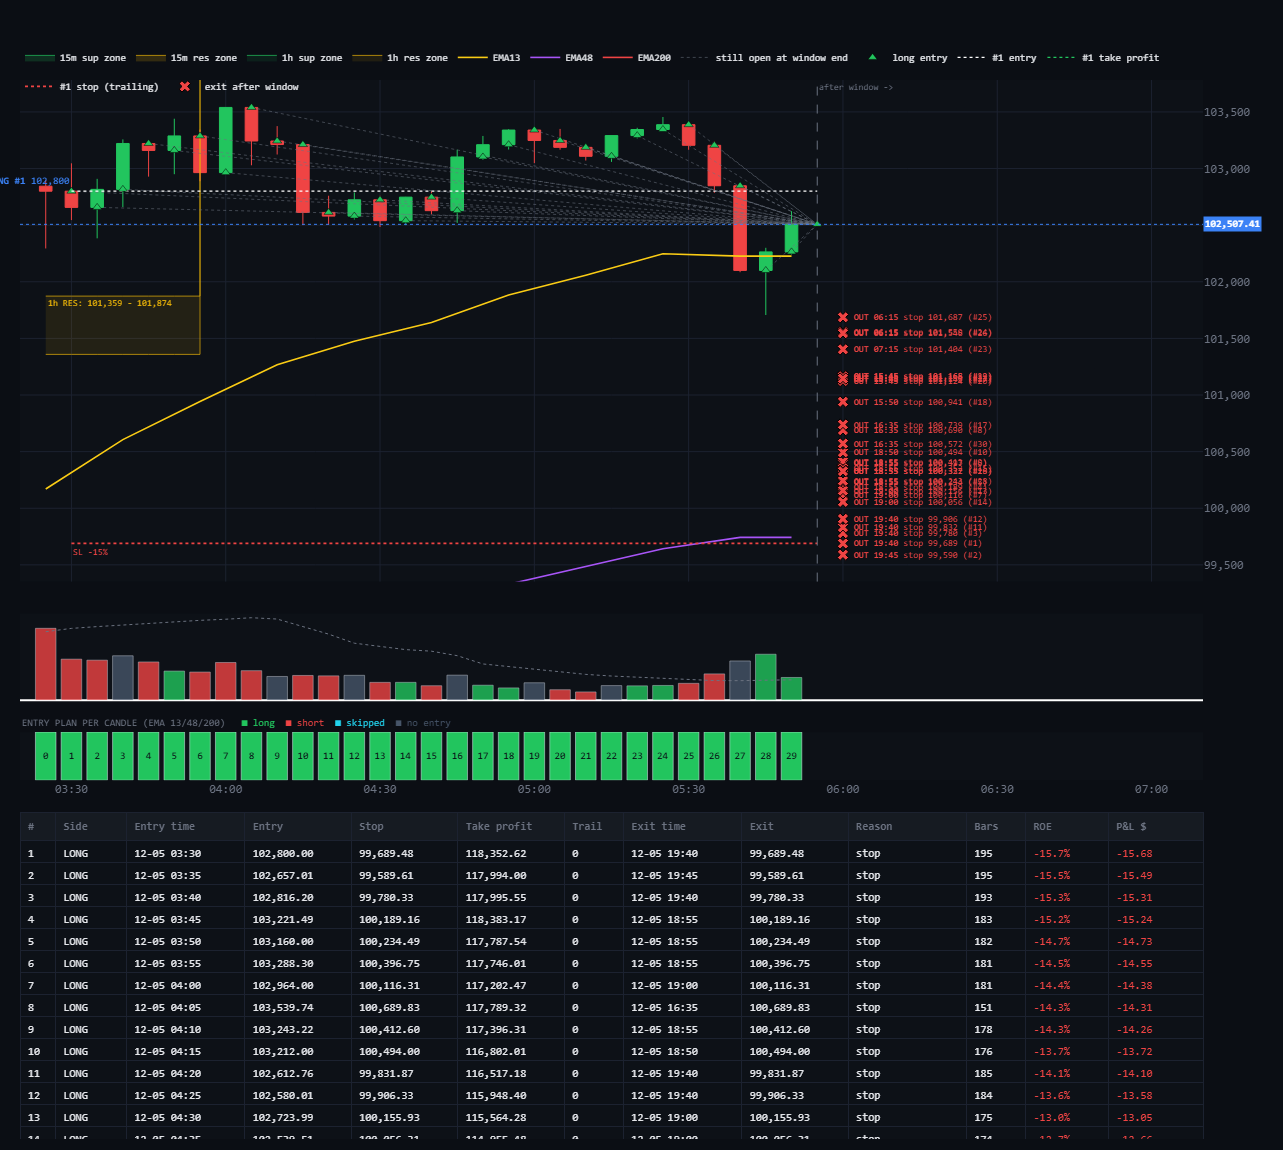

In [18]:
chart.plot_window(win, MARGIN_USDT, SHOW_ZONES, HIGHLIGHT, zoom=ZOOM).show()

## 4. Momentum move (no stop loss)

**4a - entries in this window:** each momentum entry held until the momentum ends.

| column | meaning |
|---|---|
| `mfe_atr` | best price move in favour while the momentum lasts (ATR) |
| `mae_atr` | worst price move against (ATR, ≤ 0) |
| `end_atr` | move from entry to the exit (open of the first candle without momentum) |
| `bars` | 5m candles held |

In [24]:
mv_win = window_moves(win)
tables.moves(mv_win)

27 entries | LONG 27 · SHORT 0 | median best move +0.66 ATR | median worst -0.94 ATR | exit in profit 33%


,time,side,entry,atr,mfe_atr,mae_atr,end_atr,bars
1,12-05 03:25,LONG,"102,800.00",622.10,+1.20,-0.67,+0.08,26
2,12-05 03:30,LONG,"102,657.01",613.48,+1.45,-0.45,+0.31,25
3,12-05 03:35,LONG,"102,816.20",607.17,+1.20,-0.55,+0.05,24
4,12-05 03:40,LONG,"103,221.49",606.47,+0.53,-1.22,-0.62,23
5,12-05 03:45,LONG,"103,160.00",585.10,+0.66,-1.16,-0.53,22
6,12-05 03:50,LONG,"103,288.30",578.31,+0.44,-1.39,-0.76,21
7,12-05 03:55,LONG,"102,964.00",569.54,+1.02,-0.84,-0.20,20
8,12-05 04:00,LONG,"103,539.74",569.98,+0.01,-1.85,-1.21,19
9,12-05 04:05,LONG,"103,243.22",566.12,+0.37,-1.34,-0.70,18
10,12-05 04:10,LONG,"103,212.00",543.60,+0.45,-1.34,-0.67,17


**4b - all data for `MOVE_SYMBOLS`:** how far a perfect momentum entry moves, per coin and per side.

`reach +k ATR %` = share of entries whose best move in favour reached k × ATR.

In [25]:
mv = momentum_moves(MOVE_SYMBOLS, EMA_SET, slope_min=SLOPE_MIN)
print(f'{len(mv):,} momentum entries | EMA {EMA_SET}')
tables.move_summary(summary(mv))

102,104 momentum entries | EMA 13_48_200


,BTCUSDT
metric,
entries,"102,104"
mfe median (ATR),+1.46
mfe mean (ATR),+3.21
mfe p75 (ATR),+3.78
mfe p90 (ATR),+7.98
reach +1 ATR %,58.8%
reach +2 ATR %,41.8%
reach +3 ATR %,30.8%
reach +5 ATR %,18.6%


In [26]:
tables.move_summary(summary(mv, by='side'))

,LONG,SHORT,ALL
metric,,,
entries,"54,770","47,334","102,104"
mfe median (ATR),+1.42,+1.50,+1.46
mfe mean (ATR),+3.16,+3.27,+3.21
mfe p75 (ATR),+3.69,+3.87,+3.78
mfe p90 (ATR),+8.06,+7.89,+7.98
reach +1 ATR %,58.3%,59.3%,58.8%
reach +2 ATR %,41.2%,42.4%,41.8%
reach +3 ATR %,30.3%,31.4%,30.8%
reach +5 ATR %,18.3%,19.1%,18.6%
